# Time-Series data and RNNs

In [12]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [13]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Sequential dataset: Sunspots

[Monthly mean total sunspot number](https://www.sidc.be/SILSO/infosnmtot)

[Direct link](https://www.sidc.be/SILSO/INFO/snmtotcsv.php)

In [14]:
df = pd.read_csv('~/data10/SN_m_tot_V2.0.csv', names=['Year', 'Month', 'date_frac', 'Sunspots', 'std', 'n_obs', 'definitive'], delimiter=';')
df['date'] = pd.to_datetime({'year': df['Year'], 'month': df['Month'], 'day':1})
df.head()

,Year,Month,date_frac,Sunspots,std,n_obs,definitive,date
0,1749,1,1749.042,96.7,-1.0,-1,1,1749-01-01
1,1749,2,1749.123,104.3,-1.0,-1,1,1749-02-01
2,1749,3,1749.204,116.7,-1.0,-1,1,1749-03-01
3,1749,4,1749.288,92.8,-1.0,-1,1,1749-04-01
4,1749,5,1749.371,141.7,-1.0,-1,1,1749-05-01


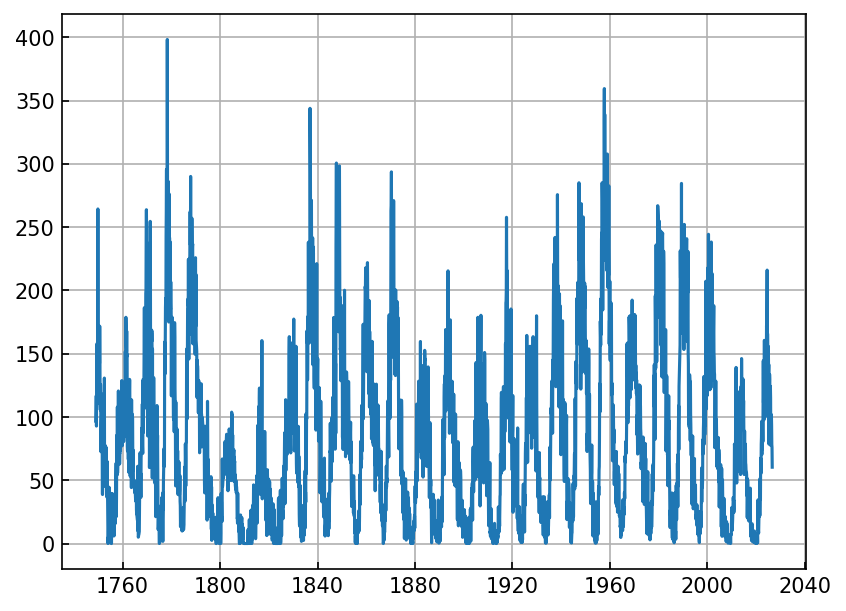

In [15]:
ax = plt.figure().gca()
ax.plot(df.date, df.Sunspots)

RNN Train Dataset has 2908 sequences
RNN Test Dataset has 375 sequences


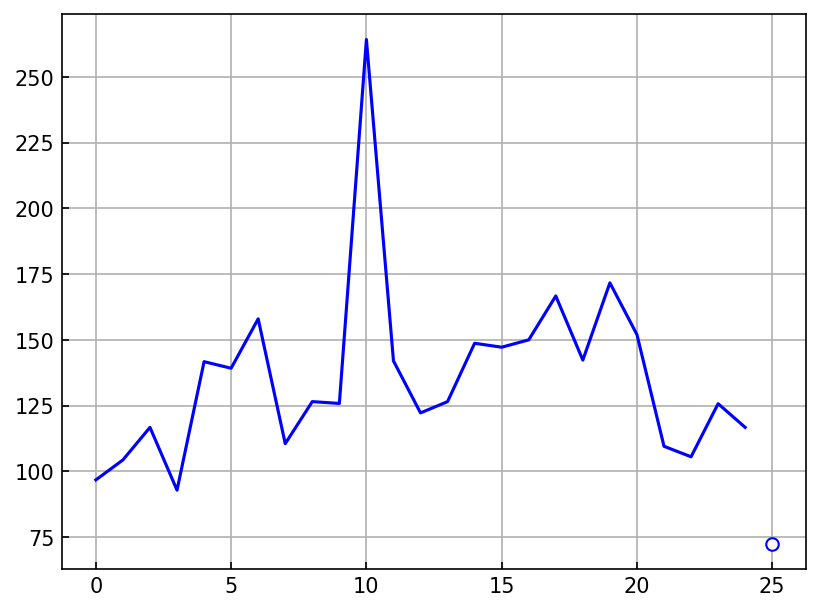

In [16]:
from torch.utils.data import Dataset

class SequenceDataset(Dataset):
    def __init__(self, df, seq_len=25, seq_stride=1):
        self.df = df
        self.seq_len = seq_len
        self.seq_stride = seq_stride

    def __len__(self):
        return len(self.df) - self.seq_len * self.seq_stride

    def __getitem__(self, idx):
        """ Return a sequence of length self.seq_len with stride self.seq_stride
            paired with the next element of the sequence
        """
        slc = slice(idx, idx + (self.seq_len + 1) * self.seq_stride, self.seq_stride)
        x = self.df['Sunspots'].values[slc, None]
        x = torch.FloatTensor(x)
        return x[:-1], x[-1] # For each element, predict the next element in the sequence

train_seqs = df.iloc[:-400]
test_seqs = df.iloc[-400:]

train_val_dataset = SequenceDataset(train_seqs)
print(f"RNN Train Dataset has {len(train_val_dataset)} sequences")

test_dataset = SequenceDataset(test_seqs)
print(f"RNN Test Dataset has {len(test_dataset)} sequences")

x, y = train_val_dataset[0]

ax = plt.figure().gca()
t = np.arange(len(x))
ax.plot(t, x[:, 0], color='blue')
ax.plot(t[-1] + 1, y[0], color='blue', marker='o', markerfacecolor='white')

## A simple baseline for time-series forecasting

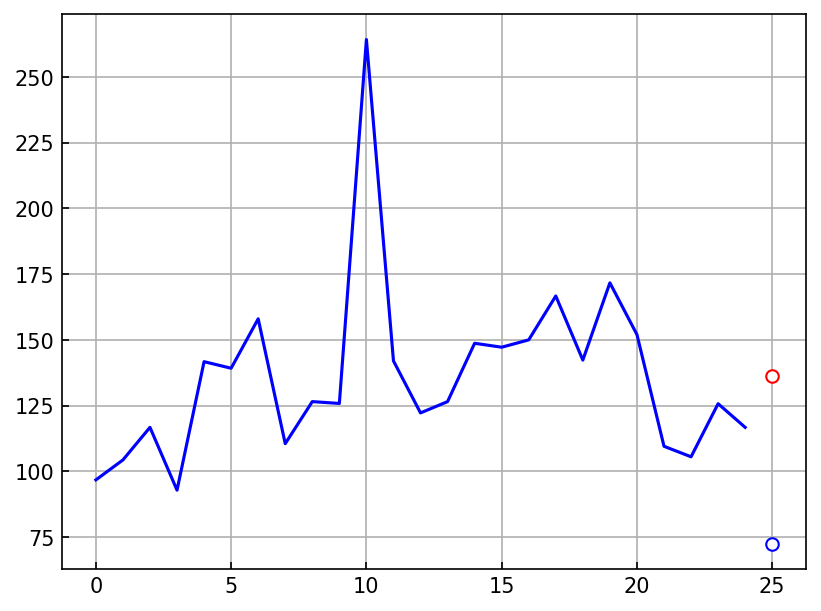

In [17]:
# Simple option - take the average of the lookback-window
x, y = train_val_dataset[0]

ax = plt.figure().gca()
t = np.arange(len(x))
ax.plot(t, x[:, 0], color='blue')
ax.plot(t[-1] + 1, y[0], color='blue', marker='o', markerfacecolor='white')

y_pred = x.mean(dim=0)
ax.plot(t[-1] + 1, y_pred, color='red', marker='o', markerfacecolor='white')

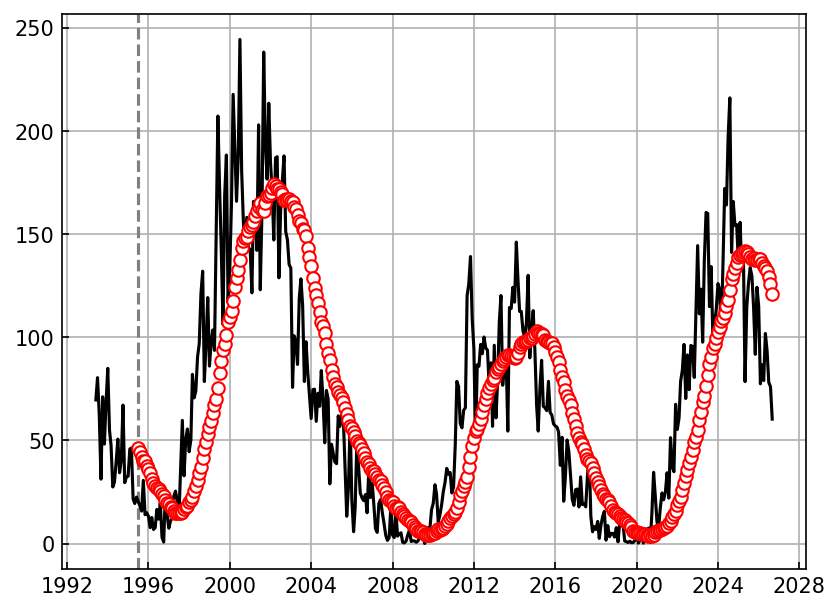

In [18]:
# Simple option - take the average of the lookback-window
# Iterate through the whole test dataset and see how it does
ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

tt = test_dataset.seq_len
for idx in range(len(test_dataset)):
    x, y = test_dataset[idx]
    y_pred = x.mean(dim=0)
    ax.plot(test_dataset.df.date.iloc[tt], y_pred, color='red', marker='o', markerfacecolor='white')
    tt += 1

[Text(0, 0.5, 'Sunspots')]

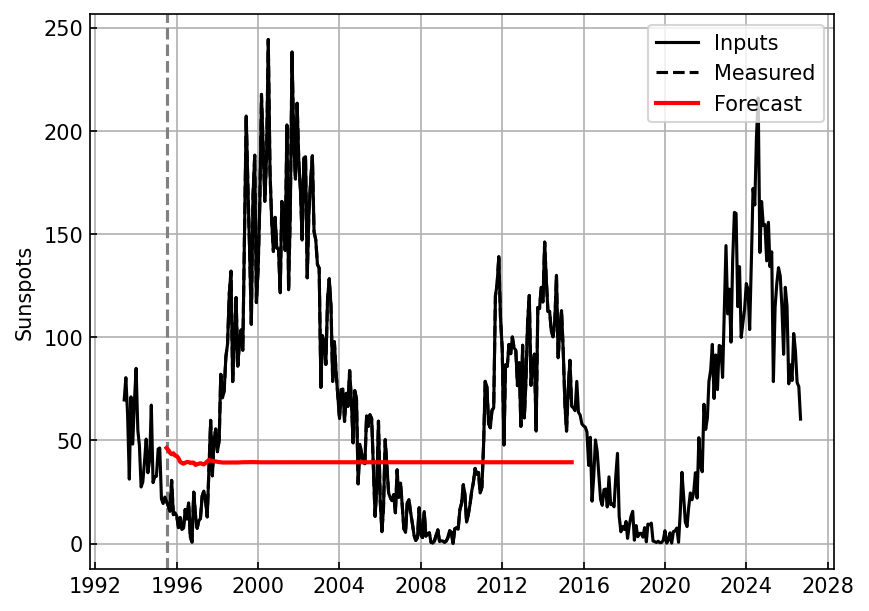

In [19]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]

# What if we want to forecast many months out?
forecast_len = 240

y_pred = []

with torch.no_grad():
    for ii in range(forecast_len):
        y_out = x_in.mean(dim=0)
        y_pred.append(y_out.numpy())
        x_in = torch.concat([x_in[1:], y_out[:, None]])
    y_pred = np.concatenate(y_pred)

ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_pred)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_pred)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_pred, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    ylabel='Sunspots'
)

## Another baseline (ARIMA)

278


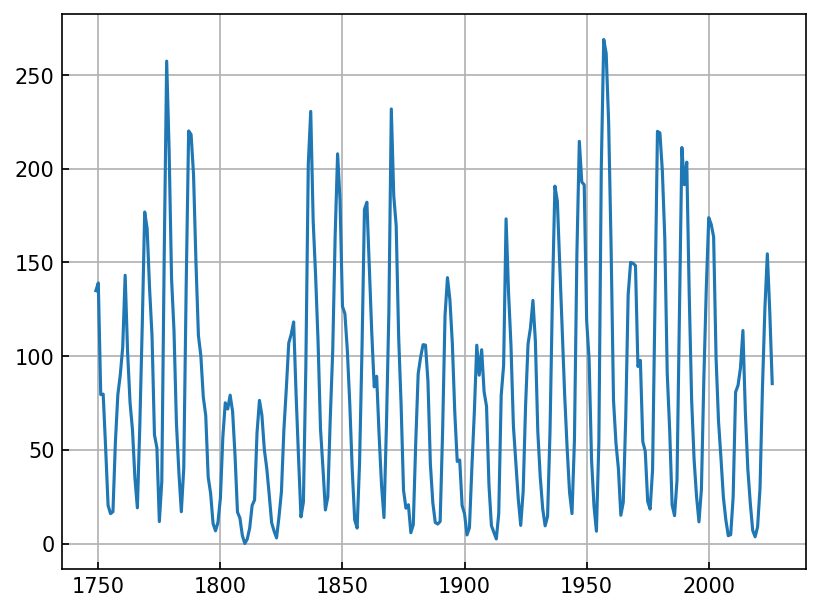

In [20]:
# Sum by year because otherwise this takes forever
year_df = df.groupby('Year').agg({'Sunspots': lambda x : x.mean()}).reset_index()
print(len(year_df))
ax = plt.figure().gca()
ax.plot(year_df.Year, year_df.Sunspots)

In [27]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.api import qqplot

forecast_years = 30
df_train = year_df.iloc[:-forecast_years]
df_test = year_df.iloc[-forecast_years:]

model = ARIMA(df_train['Sunspots'], order=(11, 0, 0)).fit()

Mean absolute deviation: 35 spots / year


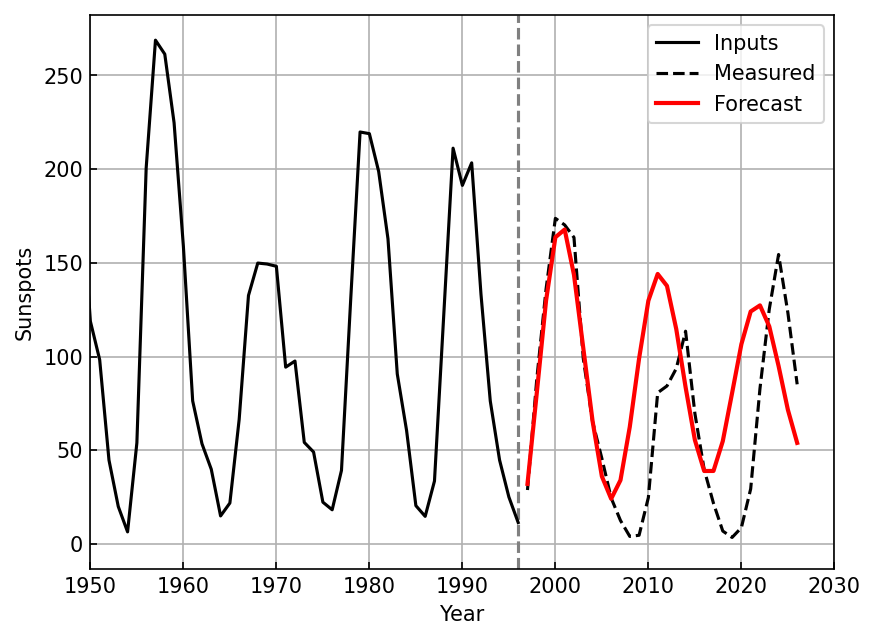

In [28]:
y_pred = model.forecast(steps=forecast_years).values

ax = plt.figure().gca()
ax.axvline(df_train.Year.iloc[-1], color='grey', linestyle='--')
ax.plot(df_train.Year, df_train.Sunspots, color='black', label='Inputs')

ax.plot(df_test.Year, df_test.Sunspots, color='black', linestyle='--', label='Measured')
ax.plot(df_test.Year, y_pred, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    xlim=[1950, 2030],
    xlabel='Year',
    ylabel='Sunspots'
)

print(f'Mean absolute deviation: {np.mean(np.abs(y_pred - df_test.Sunspots)):.0f} spots / year')

In [31]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(df_train['Sunspots'],
                order=(1, 0, 0),
                seasonal_order=(1, 0, 1, 11)).fit(disp=False)

Mean absolute deviation: 22 spots / year


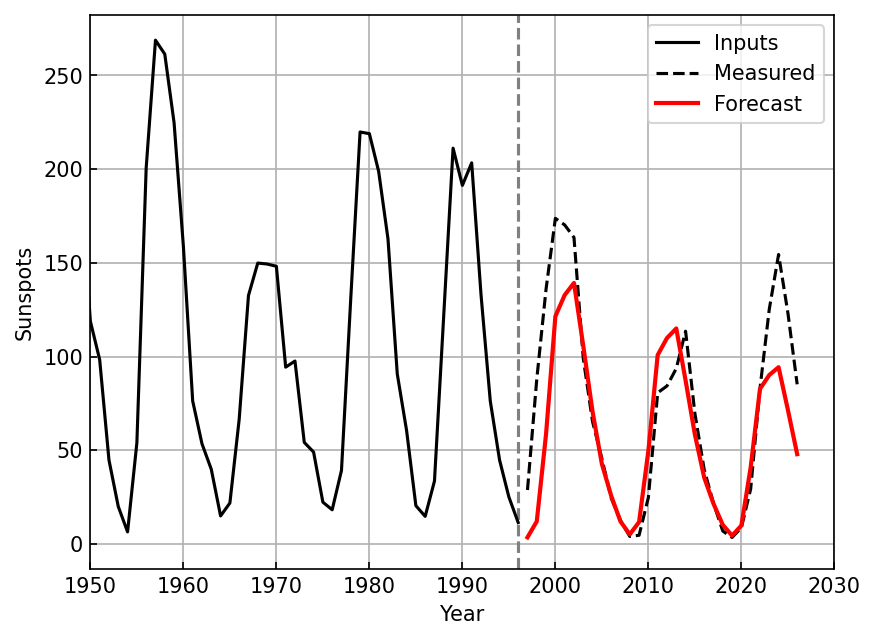

In [32]:
y_pred = model.forecast(steps=forecast_years).values

ax = plt.figure().gca()
ax.axvline(df_train.Year.iloc[-1], color='grey', linestyle='--')
ax.plot(df_train.Year, df_train.Sunspots, color='black', label='Inputs')

ax.plot(df_test.Year, df_test.Sunspots, color='black', linestyle='--', label='Measured')
ax.plot(df_test.Year, y_pred, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    xlim=[1950, 2030],
    xlabel='Year',
    ylabel='Sunspots'
)

print(f'Mean absolute deviation: {np.mean(np.abs(y_pred - df_test.Sunspots)):.0f} spots / year')

## RNN Training

In [34]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm.notebook import trange, tqdm

def train(model, optimizer, loss_func, train_dataset, val_dataset, batch_size=64, num_epochs=10, num_workers=4):
    model = model.to(device)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss = []
    train_mad = []
    val_loss = []
    val_mad = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_mad_ = 0.
        for xb, yb in train_loader:
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb)
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_mad.append(train_mad_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_mad_ = 0.
            for xb, yb in val_loader:
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb)
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
                
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_mad.append(val_mad_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_MAD=f"{train_mad[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_MAD=f"{val_mad[-1]:.3f}")
        # Consider early stopping
        # Consider learning rate scheduling

    return model, (train_loss, train_mad, val_loss, val_mad)

In [35]:
class RNN_Sequence_Forecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 128, num_layers=1, batch_first=True)
        self.linear = nn.Linear(128, 1)
        
    def forward(self, x):
        output, (hn, cn) = self.lstm(x)
        output = self.linear(output[:, -1])
        return output

from torch.utils.data import random_split
torch.manual_seed(42)
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])

rnn_model = RNN_Sequence_Forecast().to(device)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=1e-3)
rnn_model, rnn_stats = train(rnn_model, optimizer, loss, train_dataset, val_dataset, num_epochs=50)

  0%|          | 0/50 [00:00<?, ?it/s]

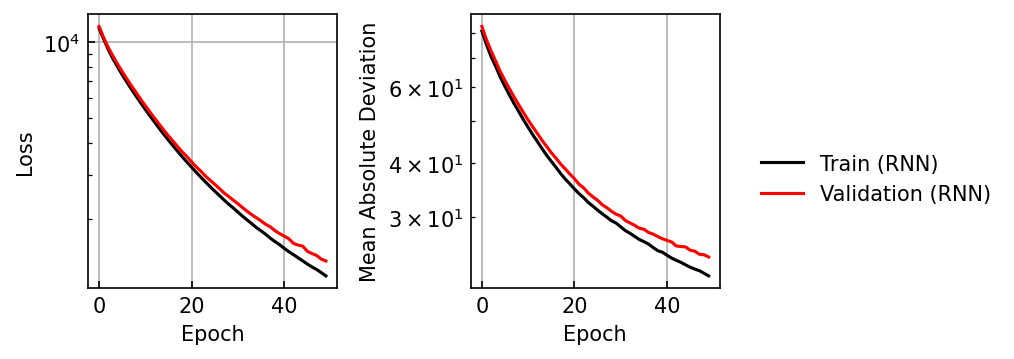

In [36]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(rnn_stats[0], color='black', label='Train (RNN)')
ax[0].plot(rnn_stats[2], color='red', label='Validation (RNN)')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(rnn_stats[1], color='black', label='Train (RNN)')
ax[1].plot(rnn_stats[3], color='red', label='Validation (RNN)')
ax[1].set(xlabel='Epoch', ylabel='Mean Absolute Deviation', yscale='log')

fig.legend(*ax[1].get_legend_handles_labels(), 
        loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

Mean absolute deviation: 36 sunspots / year


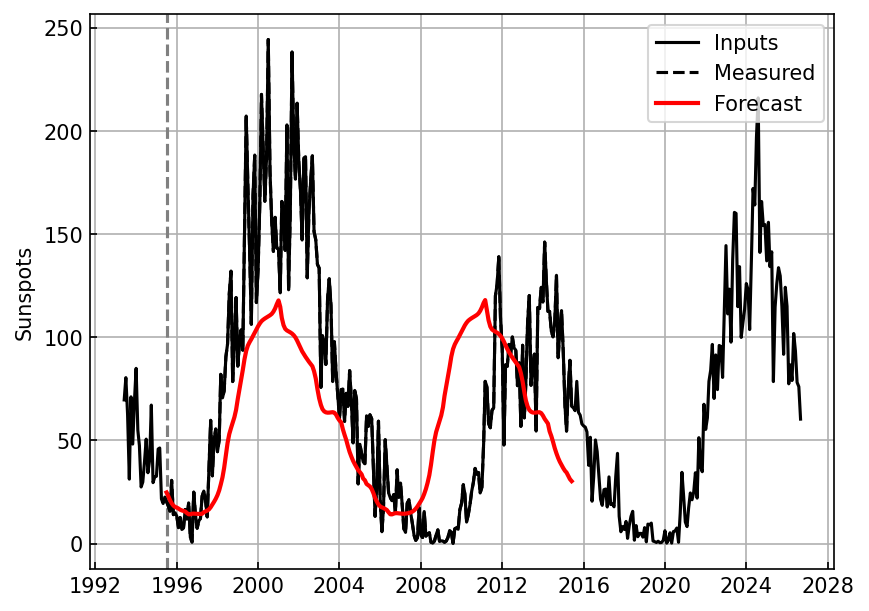

In [40]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]
forecast_len = 20 * 12 # Predict one decade
with torch.no_grad():
    x_in = torch.FloatTensor(x_in).to(device)
    y_rnn = []
    for ii in range(forecast_len):
        y_out = rnn_model(x_in[None])
        y_rnn.append(y_out.cpu().numpy()[0])
        x_in = torch.concat([x_in[1:], y_out])

    y_rnn = np.array(y_rnn)
    
ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_rnn)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_rnn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(ylabel='Sunspots')

eval_df = test_dataset.df.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)].copy()
eval_df['Predicted'] = y_rnn
eval_df = eval_df.groupby('Year')[['Sunspots', 'Predicted']].mean()
mad = np.mean(np.abs(eval_df['Sunspots'] - eval_df['Predicted']))
print(f'Mean absolute deviation: {mad:.0f} sunspots / year')

## RNN forecasting with residual connections

A residual connection on RNN outputs is analagous to the discrete form of a differential equation
\begin{align*}
    y(t + \Delta t) &= y(t) + RNN(t) \, \Delta t \\
    \\
    \rightarrow RNN(t) &= \frac{y(t + \Delta t) - y(t)}{\Delta t} \approx \frac{d y}{dt}
\end{align*}

A continuous analogue which is both interesting and useful is [NeuralODE](https://arxiv.org/abs/1806.07366)

In [42]:
class Residual_Sequence_Forecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 128, num_layers=1, batch_first=True)
        self.linear = nn.Linear(128, 1)
        
    def forward(self, x):
        output, (hn, cn) = self.lstm(x)
        output = self.linear(output[:, -1])
        return output + x[:, -1]

res_model = Residual_Sequence_Forecast().to(device)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(res_model.parameters(), lr=1e-3)
res_model, res_stats = train(res_model, optimizer, loss, train_dataset, val_dataset, num_epochs=50)

  0%|          | 0/50 [00:00<?, ?it/s]

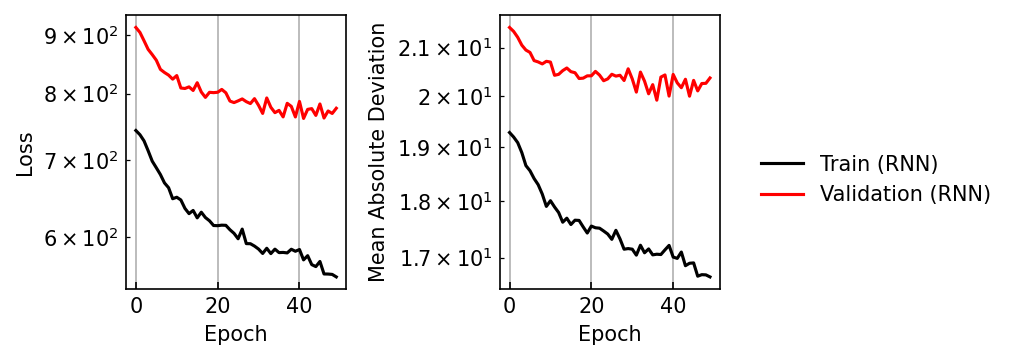

In [43]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(res_stats[0], color='black', label='Train (RNN)')
ax[0].plot(res_stats[2], color='red', label='Validation (RNN)')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(res_stats[1], color='black', label='Train (RNN)')
ax[1].plot(res_stats[3], color='red', label='Validation (RNN)')
ax[1].set(xlabel='Epoch', ylabel='Mean Absolute Deviation', yscale='log')

fig.legend(*ax[1].get_legend_handles_labels(), 
        loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

Mean absolute deviation: 31 sunspots / year


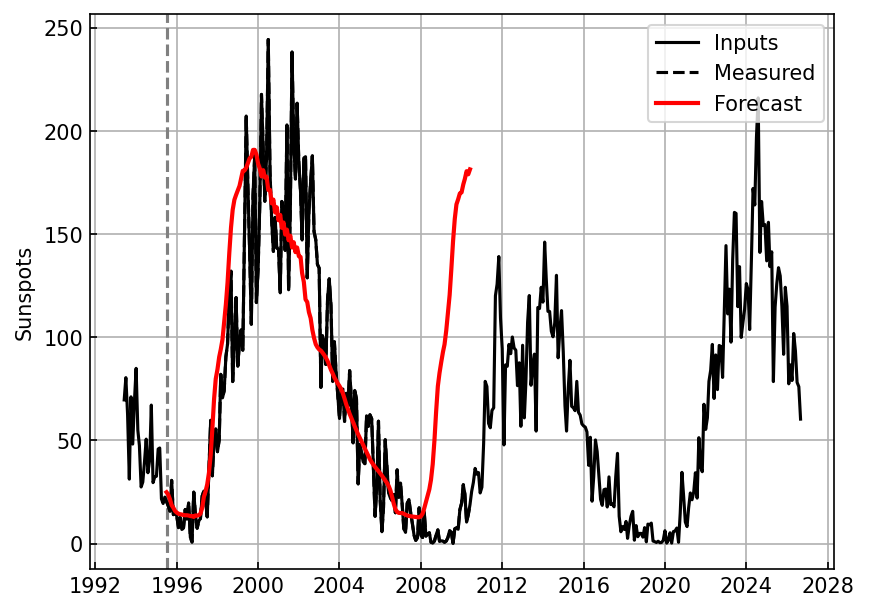

In [45]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]
forecast_len = 15 * 12 # Predict one decade
with torch.no_grad():
    x_in = torch.FloatTensor(x_in).to(device)
    y_rnn = []
    for ii in range(forecast_len):
        y_out = res_model(x_in[None])
        y_rnn.append(y_out.cpu().numpy()[0])
        x_in = torch.concat([x_in[1:], y_out])

    y_rnn = np.array(y_rnn)

ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_rnn)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_rnn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(ylabel='Sunspots')

eval_df = test_dataset.df.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)].copy()
eval_df['Predicted'] = y_rnn
eval_df = eval_df.groupby('Year')[['Sunspots', 'Predicted']].mean()
mad = np.mean(np.abs(eval_df['Sunspots'] - eval_df['Predicted']))
print(f'Mean absolute deviation: {mad:.0f} sunspots / year')

## Reservoir computing

A reservoir computer is a recurrent neural network variant whose hidden state weights are frozen. The state transitions are modeled using a "reservoir" which in general has the following properties:

- The reservoir is big, and the RNN hidden state is a high-dimensional vector
- The reservoir is sparse, so that the hidden state elements do not interact much
- The resevoir is random, so that there is a broad range of hidden state dynamics
- The resevoir is contracting, so that signals do not explode or persist indefinitely

Once initialized, we couple inputs to the reservoir via another frozen random matrix. The "training" task requires learning the output weight matrix that maps hidden states to dynamics predictions. Typically, this is done via linear regression. 

Additional reading: [[1]](https://www.science.org/doi/10.1126/science.1091277) [[2]](https://cenl.ucsd.edu/CompNeuro/Readings/week13/Lukosevicius-Jaeger+Reservoir-computing-recurrent-neural-network+CompSciRev+2019.pdf) [[3]](https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.120.024102)

In [ ]:
from scipy import sparse
from sklearn.linear_model import Ridge

def random_sparse_matrix(N, degree=3, spectral_radius=0.9):
    # Random symmetric, sparsely connected graph adjecency matrix

class EchoStateNetwork:
    def __init__(self,
                 data_dim=1,
                 reservoir_dim=1500,
                 spectral_radius=0.6,
                 avg_degree=3,
                 read_in_size=0.1,
                 l2_weight=1e-4,
                 noise=1e-3,
                 random_seed=42):
        self.data_dim = data_dim
        self.reservoir_dim = reservoir_dim
        self.spectral_radius = spectral_radius
        self.avg_degree = avg_degree
        self.l2_weight = l2_weight
        self.noise = noise

        # Initialize weights
        print('Initializing reservoir weights', flush=True)
        np.random.seed(random_seed)

        # Initialize random input weights to the reservoir
        print('Initializing input weights')

    def _step(self, input_state, hidden_state):
        """ Perform a reservoir update step
        """

    def fit(self, X, transient=100):
        """ Fit the reservoir readout weights
            X is a sequence of size [N, d]
        """
        print('Starting to fit', flush=True)
        # Compute the hidden states at each element of the sequence

        print('Solving for readout weights', flush=True)

        # Save for continuation prediction

        return self
    
    def predict(self, N, input_state=None, hidden_state=None):
        """ Make a prediction given a new input
        """
        # Pick up from where we left off
        if input_state is None:
            input_state = self.last_out
        if hidden_state is None:
            hidden_state = self.last_hidden

In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter

scaler = StandardScaler()

forecast_months = 30 * 12 # Forecast for 3 decades
x_train = df['Sunspots'].values[:-forecast_months, None]
x_train = savgol_filter(x_train, window_length=12, polyorder=1, axis=0)
x_test = df['Sunspots'].values[-forecast_months:, None]

esn_model = EchoStateNetwork(reservoir_dim=1500)
esn_model.fit(scaler.fit_transform(x_train))

y_esn = scaler.inverse_transform(esn_model.predict(len(x_test)))

ax = plt.figure().gca()
ax.axvline(df.date.iloc[-forecast_months], color='grey', linestyle='--')
ax.plot(df.date.iloc[:-forecast_months], 
        df.Sunspots.iloc[:-forecast_months], 
        color='black', label='Inputs')

ax.plot(df.date.iloc[-forecast_months:], df.Sunspots.iloc[-forecast_months:], color='black', linestyle='--', label='Measured')
ax.plot(df.date.iloc[-forecast_months:], y_esn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

import datetime
ax.set(
    xlim=[datetime.date(1950, 1, 1), datetime.date(2030, 1, 1)],
    ylabel='Sunspots'
);